In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install torch-geometric

In [ ]:
# Fair Disease Prediction from Patient Interaction Networks
# CS 517: Socially Responsible AI - Project Implementation
# Group: Skrillex AI

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix
import torch
import torch_geometric
from torch_geometric.data import Data, DataLoader
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv
import networkx as nx
import gzip

# Base path to your local MIMIC-III files
BASE_PATH = '/content/drive/MyDrive/physionet.org/files/mimiciii/1.4/'

#####################################################
# WEEK 8-9: Data Acquisition and Preprocessing
#####################################################

# Helper function to load gzipped CSV files
def load_csv_gz(file_path):
    """Load gzipped CSV file into a pandas DataFrame."""
    with gzip.open(file_path, 'rt') as f:
        return pd.read_csv(f, low_memory=False)

# 1. Extract relevant patient cohorts and features from MIMIC-III

def query_mimic_patients():
    """Query patient demographics from MIMIC-III."""
    # Load required files
    patients_df = load_csv_gz(os.path.join(BASE_PATH, 'PATIENTS.csv.gz'))
    admissions_df = load_csv_gz(os.path.join(BASE_PATH, 'ADMISSIONS.csv.gz'))

    # Merge patients and admissions
    df = pd.merge(
        patients_df,
        admissions_df,
        on='SUBJECT_ID',
        how='inner'
    )

    # Convert date columns to datetime
    df['DOB'] = pd.to_datetime(df['DOB'])
    df['ADMITTIME'] = pd.to_datetime(df['ADMITTIME'])

    # Calculate age at admission
    df['age'] = (df['ADMITTIME'].dt.year - df['DOB'].dt.year)

    # Filter adults and rename columns to match original format
    result = df[df['age'] >= 18]
    result = result.rename(columns={
        'SUBJECT_ID': 'subject_id',
        'GENDER': 'gender',
        'DOB': 'dob',
        'ETHNICITY': 'ethnicity',
        'INSURANCE': 'insurance',
        'HADM_ID': 'hadm_id'
    })

    # Select columns in same order as original function
    return result[['subject_id', 'gender', 'dob', 'ethnicity', 'insurance', 'age', 'hadm_id']]

def query_patient_diagnoses():
    """Query patient diagnoses from MIMIC-III."""
    # Load required files
    diagnoses_df = load_csv_gz(os.path.join(BASE_PATH, 'DIAGNOSES_ICD.csv.gz'))
    icd_df = load_csv_gz(os.path.join(BASE_PATH, 'D_ICD_DIAGNOSES.csv.gz'))

    # Merge diagnoses with ICD codes
    df = pd.merge(
        diagnoses_df,
        icd_df,
        on='ICD9_CODE',
        how='left'
    )

    # Rename columns to match original format
    df = df.rename(columns={
        'SUBJECT_ID': 'subject_id',
        'HADM_ID': 'hadm_id',
        'ICD9_CODE': 'icd9_code',
        'SEQ_NUM': 'seq_num',
        'LONG_TITLE': 'diagnosis_description'
    })

    # Sort as in original function
    df = df.sort_values(by=['subject_id', 'hadm_id', 'seq_num'])

    # Select columns in same order as original function
    return df[['subject_id', 'hadm_id', 'icd9_code', 'seq_num', 'diagnosis_description']]

def query_lab_results():
    """Query key lab results from MIMIC-III."""
    # Load required files
    lab_df = load_csv_gz(os.path.join(BASE_PATH, 'LABEVENTS.csv.gz'))
    items_df = load_csv_gz(os.path.join(BASE_PATH, 'D_LABITEMS.csv.gz'))

    # Rename columns to match original format
    lab_df = lab_df.rename(columns={
        'SUBJECT_ID': 'subject_id',
        'HADM_ID': 'hadm_id',
        'ITEMID': 'itemid',
        'VALUENUM': 'valuenum',
        'VALUEUOM': 'valueuom',
        'CHARTTIME': 'charttime'
    })

    items_df = items_df.rename(columns={
        'ITEMID': 'itemid',
        'LABEL': 'label'
    })

    # Merge lab events with items
    df = pd.merge(
        lab_df,
        items_df,
        on='itemid',
        how='inner'
    )

    # Filter for relevant lab tests and non-null values
    relevant_labs = [
        'Glucose', 'Creatinine', 'Sodium', 'Potassium', 'Hemoglobin',
        'White Blood Cells', 'Platelet Count', 'BUN', 'HCO3', 'Calcium',
        'Magnesium', 'Chloride', 'Anion Gap', 'pH', 'Lactate', 'Troponin I',
        'Troponin T', 'CRP', 'ALT (SGPT)', 'AST (SGOT)', 'Total Bilirubin'
    ]

    df = df[
        (df['valuenum'].notnull()) &
        (df['hadm_id'].notnull()) &
        (df['label'].isin(relevant_labs))
    ]

    # Select columns in same order as original function
    return df[['subject_id', 'hadm_id', 'itemid', 'label', 'valuenum', 'valueuom', 'charttime']]

def query_medications():
    """Query medications administered from MIMIC-III."""
    # Load prescriptions file
    prescriptions_df = load_csv_gz(os.path.join(BASE_PATH, 'PRESCRIPTIONS.csv.gz'))

    # Rename columns to match original format
    df = prescriptions_df.rename(columns={
        'SUBJECT_ID': 'subject_id',
        'HADM_ID': 'hadm_id',
        'DRUG': 'drug',
        'FORMULARY_DRUG_CD': 'formulary_drug_cd',
        'STARTDATE': 'startdate'
    })

    # Filter for non-null hospital admissions
    df = df[df['hadm_id'].notnull()]

    # Sort as in original function
    df = df.sort_values(by=['subject_id', 'hadm_id', 'startdate'])

    # Select columns in same order as original function
    return df[['subject_id', 'hadm_id', 'drug', 'formulary_drug_cd', 'startdate']]

In [ ]:
# 2. Preprocess the extracted data

def preprocess_patients(patients_df):
    """Preprocess patient demographic data."""
    # Clean and standardize ethnicity
    ethnicity_map = {
        'WHITE': 'White',
        'BLACK': 'Black',
        'HISPANIC/LATINO': 'Hispanic',
        'ASIAN': 'Asian',
        'OTHER': 'Other',
        'UNKNOWN': 'Unknown'
    }

    # Apply mapping - convert ethnicity to standardized categories
    patients_df['ethnicity_group'] = patients_df['ethnicity'].apply(
        lambda x: next((v for k, v in ethnicity_map.items() if k in x.upper()), 'Other')
    )

    # Encode gender
    patients_df['gender_encoded'] = patients_df['gender'].map({'M': 0, 'F': 1})

    # Encode insurance status (proxy for socioeconomic status)
    insurance_map = {'Medicare': 0, 'Medicaid': 1, 'Private': 2, 'Self Pay': 3, 'Government': 4}
    patients_df['insurance_encoded'] = patients_df['insurance'].apply(
        lambda x: next((v for k, v in insurance_map.items() if k in x), 4)
    )

    # Age groups (for fairness analysis)
    bins = [18, 35, 50, 65, 80, 200]
    labels = ['18-34', '35-49', '50-64', '65-79', '80+']
    patients_df['age_group'] = pd.cut(patients_df['age'], bins=bins, labels=labels, right=False)

    return patients_df

def aggregate_lab_values(lab_df):
    """Aggregate lab values by patient admission."""
    # Get the most recent value for each lab test per admission
    lab_df = lab_df.sort_values(['subject_id', 'hadm_id', 'itemid', 'charttime'])
    recent_labs = lab_df.groupby(['subject_id', 'hadm_id', 'itemid']).last().reset_index()

    # Pivot to have one row per admission with multiple lab columns
    lab_pivot = recent_labs.pivot_table(
        index=['subject_id', 'hadm_id'],
        columns='label',
        values='valuenum',
        aggfunc='first'
    ).reset_index()

    return lab_pivot

def process_diagnoses(diag_df):
    """Process diagnosis codes into categories and extract target conditions."""
    # Define the disease prediction targets - using common chronic conditions
    target_conditions = {
        'diabetes': ['250'],  # Diabetes mellitus (starts with 250)
        'heart_failure': ['428'],  # Heart failure (starts with 428)
        'hypertension': ['401', '402', '403', '404', '405'],  # Hypertension
        'copd': ['490', '491', '492', '493', '494', '495', '496'],  # COPD & asthma
        'ckd': ['585'],  # Chronic kidney disease (starts with 585)
        'cad': ['410', '411', '412', '413', '414']  # Coronary artery disease
    }

    # First convert icd9_code to string and handle NaN values
    diag_df['icd9_code'] = diag_df['icd9_code'].astype(str)

    # Create target variables for each condition
    patient_conditions = pd.DataFrame()
    patient_conditions['subject_id'] = diag_df['subject_id'].unique()

    for condition, codes in target_conditions.items():
        # Create a set of all diagnoses for each patient
        patient_diagnoses = diag_df.groupby('subject_id')['icd9_code'].apply(set).reset_index()

        # Check if any diagnosis code starts with the target codes
        patient_conditions[condition] = patient_diagnoses['subject_id'].map(
            patient_diagnoses.set_index('subject_id')['icd9_code'].apply(
                lambda x: any(any(str(code).startswith(prefix) for code in x) for prefix in codes)
            )
        ).fillna(False).astype(int)

    # Create a diagnosis count feature per patient
    diagnosis_counts = diag_df.groupby('subject_id').size().reset_index(name='diagnosis_count')
    patient_conditions = patient_conditions.merge(diagnosis_counts, on='subject_id', how='left')

    return patient_conditions

def extract_medication_features(med_df):
    """Extract medication features from prescriptions data."""
    # Count unique medications per patient
    med_counts = med_df.groupby('subject_id')['drug'].nunique().reset_index(name='unique_med_count')

    # Get common medication categories
    common_med_categories = [
        'antibiotic', 'analgesic', 'antihypertensive', 'insulin',
        'statin', 'anticoagulant', 'diuretic', 'steroid'
    ]

    # Create binary indicators for each category
    for category in common_med_categories:
        med_df[f'has_{category}'] = med_df['drug'].str.lower().str.contains(category).astype(int)

    med_features = med_df.groupby('subject_id')[
        [f'has_{category}' for category in common_med_categories]
    ].max().reset_index()

    # Merge medication counts with category features
    med_features = med_features.merge(med_counts, on='subject_id', how='outer')

    return med_features

In [ ]:
# 3. Construct patient similarity networks

def create_patient_similarity_network(patient_features, threshold=0.7):
    """
    Construct patient similarity network based on clinical features.

    Args:
        patient_features: DataFrame with patient features
        threshold: Similarity threshold for creating edges

    Returns:
        NetworkX graph and torch_geometric Data object
    """
    # Extract feature matrix (without IDs and target variables)
    feature_cols = [col for col in patient_features.columns
                   if col not in ['subject_id', 'hadm_id', 'diabetes', 'heart_failure',
                                 'hypertension', 'copd', 'ckd', 'cad']]

    # Separate numerical and categorical features
    numerical_cols = patient_features[feature_cols].select_dtypes(include=['int64', 'float64']).columns.tolist()
    categorical_cols = patient_features[feature_cols].select_dtypes(include=['object', 'category']).columns.tolist()

    # Process numerical features
    X_numerical = patient_features[numerical_cols]

    # Process categorical features if present
    if categorical_cols:
        X_categorical = pd.get_dummies(patient_features[categorical_cols])
        # Combine numerical and one-hot encoded categorical features
        X_combined = pd.concat([X_numerical, X_categorical], axis=1)
    else:
        X_combined = X_numerical

    # Normalize features
    scaler = StandardScaler()
    X = scaler.fit_transform(X_combined)

    # Create similarity matrix using cosine similarity
    from sklearn.metrics.pairwise import cosine_similarity
    similarity_matrix = cosine_similarity(X)

    # Create network
    G = nx.Graph()

    # Add nodes
    for i in range(len(patient_features)):
        G.add_node(i,
                  subject_id=patient_features.iloc[i]['subject_id'],
                  features=X[i])

        # Add demographic attributes to nodes
        if 'gender_encoded' in patient_features.columns:
            G.nodes[i]['gender'] = patient_features.iloc[i]['gender_encoded']
        if 'ethnicity_group' in patient_features.columns:
            G.nodes[i]['ethnicity'] = patient_features.iloc[i]['ethnicity_group']
        if 'age_group' in patient_features.columns:
            G.nodes[i]['age_group'] = patient_features.iloc[i]['age_group']
        if 'insurance_encoded' in patient_features.columns:
            G.nodes[i]['insurance'] = patient_features.iloc[i]['insurance_encoded']

    # Add edges based on similarity threshold
    for i in range(len(patient_features)):
        for j in range(i+1, len(patient_features)):
            if similarity_matrix[i][j] > threshold:
                G.add_edge(i, j, weight=similarity_matrix[i][j])

    # Create PyTorch Geometric Data object
    edge_index = []
    edge_weight = []

    for u, v, d in G.edges(data=True):
        edge_index.append([u, v])
        edge_index.append([v, u])  # Add both directions (undirected graph)
        edge_weight.extend([d['weight'], d['weight']])

    if edge_index:  # Check if there are any edges
        edge_index = torch.tensor(edge_index).t().contiguous()
        edge_weight = torch.tensor(edge_weight, dtype=torch.float)
    else:
        # Handle case with no edges
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_weight = torch.zeros(0, dtype=torch.float)

    # Extract node features and target variables
    node_features = torch.tensor(X, dtype=torch.float)

    target_cols = ['diabetes', 'heart_failure', 'hypertension', 'copd', 'ckd', 'cad']
    y = torch.tensor(patient_features[target_cols].values, dtype=torch.float)

    # Create PyG Data object
    data = Data(x=node_features,
                edge_index=edge_index,
                edge_attr=edge_weight,
                y=y)

    # Add metadata
    data.subject_ids = patient_features['subject_id'].values

    # Add demographic information for fairness analysis
    if 'gender_encoded' in patient_features.columns:
        data.gender = torch.tensor(patient_features['gender_encoded'].values)
    if 'ethnicity_group' in patient_features.columns:
        # Convert ethnicity to numerical codes
        ethnicity_encoder = {val: idx for idx, val in enumerate(patient_features['ethnicity_group'].unique())}
        data.ethnicity = torch.tensor([ethnicity_encoder[e] for e in patient_features['ethnicity_group']])
    if 'age_group' in patient_features.columns:
        # Convert age groups to numerical codes
        age_group_encoder = {val: idx for idx, val in enumerate(patient_features['age_group'].unique())}
        data.age_group = torch.tensor([age_group_encoder[a] for a in patient_features['age_group']])
    if 'insurance_encoded' in patient_features.columns:
        data.insurance = torch.tensor(patient_features['insurance_encoded'].values)

    return G, data

def analyze_demographic_distribution(patient_data):
    """Analyze demographic distribution in the dataset."""
    # Gender distribution
    gender_dist = patient_data['gender'].value_counts(normalize=True)

    # Ethnicity distribution
    ethnicity_dist = patient_data['ethnicity_group'].value_counts(normalize=True)

    # Age group distribution
    age_dist = patient_data['age_group'].value_counts(normalize=True)

    # Insurance (socioeconomic) distribution
    insurance_dist = patient_data['insurance'].value_counts(normalize=True)

    # Disease prevalence by demographic groups
    disease_cols = ['diabetes', 'heart_failure', 'hypertension', 'copd', 'ckd', 'cad']

    # Plot disease prevalence by gender
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, disease in enumerate(disease_cols):
        disease_by_gender = patient_data.groupby('gender')[disease].mean()
        disease_by_gender.plot(kind='bar', ax=axes[i], title=f'{disease.replace("_", " ").title()} Prevalence by Gender')
        axes[i].set_ylabel('Prevalence')

    plt.tight_layout()
    plt.savefig('disease_prevalence_by_gender.png')

    # Plot disease prevalence by ethnicity
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, disease in enumerate(disease_cols):
        disease_by_ethnicity = patient_data.groupby('ethnicity_group')[disease].mean()
        disease_by_ethnicity.plot(kind='bar', ax=axes[i], title=f'{disease.replace("_", " ").title()} Prevalence by Ethnicity')
        axes[i].set_ylabel('Prevalence')

    plt.tight_layout()
    plt.savefig('disease_prevalence_by_ethnicity.png')

    return {
        'gender_distribution': gender_dist,
        'ethnicity_distribution': ethnicity_dist,
        'age_distribution': age_dist,
        'insurance_distribution': insurance_dist
    }

In [ ]:
#####################################################
# WEEK 10: Baseline Model Development
#####################################################

# 1. Graph Neural Network Models

class GCNModel(torch.nn.Module):
    """Graph Convolutional Network for disease prediction."""
    def __init__(self, num_features, hidden_channels, num_diseases):
        super(GCNModel, self).__init__()
        self.conv1 = GCNConv(num_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.lin = torch.nn.Linear(hidden_channels, num_diseases)

    def forward(self, x, edge_index, edge_weight=None):
        # First Graph Conv layer
        x = self.conv1(x, edge_index, edge_weight)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        # Second Graph Conv layer
        x = self.conv2(x, edge_index, edge_weight)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        # Output layer
        x = self.lin(x)

        return torch.sigmoid(x)  # Sigmoid for multi-label classification

class GATModel(torch.nn.Module):
    """Graph Attention Network for disease prediction."""
    def __init__(self, num_features, hidden_channels, num_diseases, heads=8):
        super(GATModel, self).__init__()
        self.conv1 = GATConv(num_features, hidden_channels // heads, heads=heads)
        self.conv2 = GATConv(hidden_channels, hidden_channels // heads, heads=heads)
        self.lin = torch.nn.Linear(hidden_channels, num_diseases)

    def forward(self, x, edge_index):
        # First Graph Attention layer
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        # Second Graph Attention layer
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)

        # Output layer
        x = self.lin(x)

        return torch.sigmoid(x)  # Sigmoid for multi-label classification

In [ ]:
# 2. Training and evaluation functions

def train_model(model, data, optimizer, device='cpu'):
    """Train a GNN model for disease prediction."""
    model.train()

    # Move data to device
    x = data.x.to(device)
    edge_index = data.edge_index.to(device)
    edge_attr = data.edge_attr.to(device) if hasattr(data, 'edge_attr') else None
    y = data.y.to(device)

    # Forward pass
    optimizer.zero_grad()

    if isinstance(model, GATModel):
        out = model(x, edge_index)
    else:  # GCN model
        out = model(x, edge_index, edge_attr)

    # Binary cross entropy loss for multi-label classification
    loss = F.binary_cross_entropy(out, y)

    # Backward pass
    loss.backward()
    optimizer.step()

    return loss.item()

def evaluate_model(model, data, device='cpu'):
    """Evaluate model performance."""
    model.eval()

    # Move data to device
    x = data.x.to(device)
    edge_index = data.edge_index.to(device)
    edge_attr = data.edge_attr.to(device) if hasattr(data, 'edge_attr') else None
    y = data.y.to(device)

    # Forward pass
    with torch.no_grad():
        if isinstance(model, GATModel):
            out = model(x, edge_index)
        else:  # GCN model
            out = model(x, edge_index, edge_attr)

    # Convert predictions to binary (threshold = 0.5)
    preds = (out > 0.5).float()

    # Calculate metrics
    accuracy = (preds == y).float().mean().item()

    # AUC scores for each disease
    auc_scores = []
    for i in range(y.shape[1]):
        if len(torch.unique(y[:, i])) > 1:  # Only calculate AUC if both classes exist
            auc = roc_auc_score(y[:, i].cpu().numpy(), out[:, i].cpu().numpy())
            auc_scores.append(auc)

    # F1 scores for each disease
    f1_scores = []
    for i in range(y.shape[1]):
        f1 = f1_score(y[:, i].cpu().numpy(), preds[:, i].cpu().numpy())
        f1_scores.append(f1)

    return {
        'accuracy': accuracy,
        'auc_scores': auc_scores,
        'mean_auc': np.mean(auc_scores) if auc_scores else 0,
        'f1_scores': f1_scores,
        'mean_f1': np.mean(f1_scores)
    }

def evaluate_fairness(model, data, device='cpu'):
    """Evaluate model fairness across demographic groups using demographic parity and equal opportunity."""
    model.eval()

    # Move data to device
    x = data.x.to(device)
    edge_index = data.edge_index.to(device)
    edge_attr = data.edge_attr.to(device) if hasattr(data, 'edge_attr') else None
    y = data.y.to(device)

    # Forward pass
    with torch.no_grad():
        if isinstance(model, GATModel):
            out = model(x, edge_index)
        else:  # GCN model
            out = model(x, edge_index, edge_attr)

    # Convert predictions to binary (threshold = 0.5)
    preds = (out > 0.5).float()

    # Move back to CPU for analysis
    y_np = y.cpu().numpy()
    preds_np = preds.cpu().numpy()

    # Initialize fairness metrics dict
    fairness_metrics = {}

    # Analyze performance by gender
    if hasattr(data, 'gender'):
        gender_np = data.gender.cpu().numpy()

        # Calculate demographic parity and equal opportunity for each gender group
        gender_metrics = {}
        for gender_val, gender_name in [(0, 'Male'), (1, 'Female')]:
            mask = gender_np == gender_val

            if np.sum(mask) > 0:  # Ensure we have samples from this group
                # Demographic Parity: Positive prediction rate
                positive_rate = preds_np[mask].mean()

                # Equal Opportunity: True Positive Rate (TPR)
                # Calculate TPR for each disease and average
                tprs = []
                for i in range(y_np.shape[1]):
                    true_positives = ((y_np[mask, i] == 1) & (preds_np[mask, i] == 1)).sum()
                    actual_positives = (y_np[mask, i] == 1).sum()
                    tpr = true_positives / actual_positives if actual_positives > 0 else 0
                    tprs.append(tpr)

                gender_metrics[gender_name] = {
                    'positive_rate': positive_rate,
                    'tpr': np.mean(tprs)
                }

        fairness_metrics['gender'] = gender_metrics

    # Analyze performance by ethnicity
    if hasattr(data, 'ethnicity'):
        ethnicity_np = data.ethnicity.cpu().numpy()
        unique_ethnicities = np.unique(ethnicity_np)

        # Calculate demographic parity and equal opportunity for each ethnicity group
        ethnicity_metrics = {}
        for eth_code in unique_ethnicities:
            eth_name = f'Ethnicity_{eth_code}'
            mask = ethnicity_np == eth_code

            if np.sum(mask) > 0:  # Ensure we have samples from this group
                # Demographic Parity: Positive prediction rate
                positive_rate = preds_np[mask].mean()

                # Equal Opportunity: True Positive Rate (TPR)
                tprs = []
                for i in range(y_np.shape[1]):
                    true_positives = ((y_np[mask, i] == 1) & (preds_np[mask, i] == 1)).sum()
                    actual_positives = (y_np[mask, i] == 1).sum()
                    tpr = true_positives / actual_positives if actual_positives > 0 else 0
                    tprs.append(tpr)

                ethnicity_metrics[eth_name] = {
                    'positive_rate': positive_rate,
                    'tpr': np.mean(tprs)
                }

        fairness_metrics['ethnicity'] = ethnicity_metrics

    if 'gender' in fairness_metrics:
        gender_groups = list(fairness_metrics['gender'].keys())
        if len(gender_groups) >= 2:
            # Demographic Parity Difference
            dp_diff = abs(
                fairness_metrics['gender'][gender_groups[0]]['positive_rate'] -
                fairness_metrics['gender'][gender_groups[1]]['positive_rate']
            )

            # Equal Opportunity Difference
            eo_diff = abs(
                fairness_metrics['gender'][gender_groups[0]]['tpr'] -
                fairness_metrics['gender'][gender_groups[1]]['tpr']
            )

            fairness_metrics['gender_disparity'] = {
                'demographic_parity_diff': dp_diff,
                'equal_opportunity_diff': eo_diff
            }

    if 'ethnicity' in fairness_metrics:
        eth_groups = list(fairness_metrics['ethnicity'].keys())
        if len(eth_groups) >= 2:
            # Find max disparity between any two groups
            max_dp_diff = 0
            max_eo_diff = 0

            for i in range(len(eth_groups)):
                for j in range(i+1, len(eth_groups)):
                    dp_diff = abs(
                        fairness_metrics['ethnicity'][eth_groups[i]]['positive_rate'] -
                        fairness_metrics['ethnicity'][eth_groups[j]]['positive_rate']
                    )
                    eo_diff = abs(
                        fairness_metrics['ethnicity'][eth_groups[i]]['tpr'] -
                        fairness_metrics['ethnicity'][eth_groups[j]]['tpr']
                    )

                    max_dp_diff = max(max_dp_diff, dp_diff)
                    max_eo_diff = max(max_eo_diff, eo_diff)

            fairness_metrics['ethnicity_disparity'] = {
                'demographic_parity_diff': max_dp_diff,
                'equal_opportunity_diff': max_eo_diff
            }

    return fairness_metrics

def visualize_fairness_disparities(fairness_metrics):
    """Visualize fairness disparities across demographic groups."""
    # Plot performance by gender
    if 'gender' in fairness_metrics:
        gender_data = fairness_metrics['gender']
        gender_labels = list(gender_data.keys())
        gender_auc = [gender_data[g]['mean_auc'] for g in gender_labels]
        gender_f1 = [gender_data[g]['mean_f1'] for g in gender_labels]

        plt.figure(figsize=(10, 6))
        bar_width = 0.35
        x = np.arange(len(gender_labels))

        plt.bar(x - bar_width/2, gender_auc, bar_width, label='Mean AUC')
        plt.bar(x + bar_width/2, gender_f1, bar_width, label='Mean F1')

        plt.xlabel('Gender')
        plt.ylabel('Score')
        plt.title('Model Performance by Gender')
        plt.xticks(x, gender_labels)
        plt.legend()
        plt.tight_layout()
        plt.savefig('gender_fairness.png')

    # Plot performance by ethnicity
    if 'ethnicity' in fairness_metrics:
        eth_data = fairness_metrics['ethnicity']
        eth_labels = list(eth_data.keys())
        eth_auc = [eth_data[e]['mean_auc'] for e in eth_labels]
        eth_f1 = [eth_data[e]['mean_f1'] for e in eth_labels]

        plt.figure(figsize=(12, 6))
        bar_width = 0.35
        x = np.arange(len(eth_labels))

        plt.bar(x - bar_width/2, eth_auc, bar_width, label='Mean AUC')
        plt.bar(x + bar_width/2, eth_f1, bar_width, label='Mean F1')
        plt.xlabel('Ethnicity')
        plt.ylabel('Score')
        plt.title('Model Performance by Ethnicity')
        plt.xticks(x, eth_labels, rotation=45, ha='right')
        plt.legend()
        plt.tight_layout()
        plt.savefig('ethnicity_fairness.png')

    # Plot disparity metrics
    disparity_metrics = {}

    if 'gender_disparity' in fairness_metrics:
        disparity_metrics['Gender'] = [
            fairness_metrics['gender_disparity']['mean_auc_diff'],
            fairness_metrics['gender_disparity']['mean_f1_diff']
        ]

    if 'ethnicity_disparity' in fairness_metrics:
        disparity_metrics['Ethnicity'] = [
            fairness_metrics['ethnicity_disparity']['max_mean_auc_diff'],
            fairness_metrics['ethnicity_disparity']['max_mean_f1_diff']
        ]

    if disparity_metrics:
        plt.figure(figsize=(10, 6))

        labels = list(disparity_metrics.keys())
        auc_diffs = [disparity_metrics[l][0] for l in labels]
        f1_diffs = [disparity_metrics[l][1] for l in labels]

        bar_width = 0.35
        x = np.arange(len(labels))

        plt.bar(x - bar_width/2, auc_diffs, bar_width, label='AUC Disparity')
        plt.bar(x + bar_width/2, f1_diffs, bar_width, label='F1 Disparity')

        plt.xlabel('Demographic Attribute')
        plt.ylabel('Maximum Performance Disparity')
        plt.title('Fairness Disparities Across Demographic Groups')
        plt.xticks(x, labels)
        plt.legend()
        plt.tight_layout()
        plt.savefig('fairness_disparities.png')



In [ ]:

# Additional utility functions for interpreting results

def plot_network_visualization(G, color_by='community'):
    """Visualize the patient similarity network."""
    plt.figure(figsize=(12, 12))

    if color_by == 'community':
        # Detect communities
        from networkx.algorithms import community
        communities = community.greedy_modularity_communities(G)

        # Create a dictionary mapping node to community
        community_map = {}
        for i, comm in enumerate(communities):
            for node in comm:
                community_map[node] = i

        # Color nodes by community
        node_colors = [community_map.get(node, 0) for node in G.nodes()]

    elif color_by == 'gender':
        # Color by gender attribute
        gender_colors = {'M': 'blue', 'F': 'red'}
        node_colors = [gender_colors.get(G.nodes[node].get('gender', 'unknown'), 'gray')
                      for node in G.nodes()]

    else:  # Default coloring
        node_colors = 'skyblue'

    # Draw the network
    pos = nx.spring_layout(G, seed=42)
    nx.draw_networkx(
        G,
        pos=pos,
        node_color=node_colors,
        node_size=50,
        with_labels=False,
        edge_color='gray',
        alpha=0.7
    )

    plt.title(f"Patient Similarity Network (Colored by {color_by})")
    plt.axis('off')
    plt.tight_layout()
    plt.savefig(f'network_by_{color_by}.png', dpi=300)

def analyze_model_predictions(model, data, device='cpu'):
    """Analyze model predictions and errors."""
    model.eval()

    # Move data to device
    x = data.x.to(device)
    edge_index = data.edge_index.to(device)
    edge_attr = data.edge_attr.to(device) if hasattr(data, 'edge_attr') else None
    y = data.y.to(device)

    # Get predictions
    with torch.no_grad():
        if isinstance(model, GATModel):
            out = model(x, edge_index)
        else:  # GCN model
            out = model(x, edge_index, edge_attr)

    # Convert to numpy for analysis
    preds = (out > 0.5).float().cpu().numpy()
    probs = out.cpu().numpy()
    y_true = y.cpu().numpy()

    # Analyze errors
    correct = (preds == y_true)
    incorrect = ~correct

    # Get demographic information
    demographics = {}
    if hasattr(data, 'gender'):
        demographics['gender'] = data.gender.cpu().numpy()
    if hasattr(data, 'ethnicity'):
        demographics['ethnicity'] = data.ethnicity.cpu().numpy()
    if hasattr(data, 'age_group'):
        demographics['age_group'] = data.age_group.cpu().numpy()
    if hasattr(data, 'insurance'):
        demographics['insurance'] = data.insurance.cpu().numpy()

    # Analyze error patterns by demographic groups
    error_analysis = {}
    disease_names = ['Diabetes', 'Heart Failure', 'Hypertension', 'COPD', 'CKD', 'CAD']

    for demo_name, demo_values in demographics.items():
        # Get unique values
        unique_values = np.unique(demo_values)

        # Create analysis per demographic group
        group_analysis = {}

        for val in unique_values:
            mask = demo_values == val
            group_name = f"{demo_name}_{val}"

            # Calculate error rates by disease
            disease_errors = {}
            for i, disease in enumerate(disease_names):
                true_pos = np.logical_and(preds[mask, i] == 1, y_true[mask, i] == 1).sum()
                true_neg = np.logical_and(preds[mask, i] == 0, y_true[mask, i] == 0).sum()
                false_pos = np.logical_and(preds[mask, i] == 1, y_true[mask, i] == 0).sum()
                false_neg = np.logical_and(preds[mask, i] == 0, y_true[mask, i] == 1).sum()

                total = mask.sum()
                if total > 0:
                    error_rate = (false_pos + false_neg) / total
                    fpr = false_pos / (false_pos + true_neg) if (false_pos + true_neg) > 0 else 0
                    fnr = false_neg / (false_neg + true_pos) if (false_neg + true_pos) > 0 else 0

                    disease_errors[disease] = {
                        'error_rate': error_rate,
                        'false_positive_rate': fpr,
                        'false_negative_rate': fnr
                    }

            group_analysis[group_name] = disease_errors

        error_analysis[demo_name] = group_analysis

    # Create visualizations for error patterns
    for demo_name, group_data in error_analysis.items():
        plt.figure(figsize=(14, 8))

        # Prepare data for plotting
        groups = list(group_data.keys())
        disease_fp_rates = {disease: [] for disease in disease_names}
        disease_fn_rates = {disease: [] for disease in disease_names}

        for group in groups:
            for disease in disease_names:
                if disease in group_data[group]:
                    disease_fp_rates[disease].append(group_data[group][disease]['false_positive_rate'])
                    disease_fn_rates[disease].append(group_data[group][disease]['false_negative_rate'])
                else:
                    disease_fp_rates[disease].append(0)
                    disease_fn_rates[disease].append(0)

        # Plot false positive rates
        plt.subplot(1, 2, 1)
        bar_width = 0.15
        x = np.arange(len(groups))

        for i, disease in enumerate(disease_names):
            plt.bar(x + i*bar_width - 0.45, disease_fp_rates[disease], bar_width, label=disease)

        plt.xlabel(demo_name.capitalize())
        plt.ylabel('False Positive Rate')
        plt.title(f'False Positive Rates by {demo_name.capitalize()}')
        plt.xticks(x, groups, rotation=45, ha='right')
        plt.legend()

        # Plot false negative rates
        plt.subplot(1, 2, 2)

        for i, disease in enumerate(disease_names):
            plt.bar(x + i*bar_width - 0.45, disease_fn_rates[disease], bar_width, label=disease)

        plt.xlabel(demo_name.capitalize())
        plt.ylabel('False Negative Rate')
        plt.title(f'False Negative Rates by {demo_name.capitalize()}')
        plt.xticks(x, groups, rotation=45, ha='right')
        plt.legend()

        plt.tight_layout()
        plt.savefig(f'error_patterns_by_{demo_name}.png')

    return error_analysis


In [ ]:
np.random.seed(42)
torch.manual_seed(42)

print("Starting MIMIC-III data extraction and preprocessing...")

# 1. Extract and preprocess data
patients_df = query_mimic_patients()
print(f"Extracted {len(patients_df)} patient records")

diagnoses_df = query_patient_diagnoses()
print(f"Extracted {len(diagnoses_df)} diagnosis records")

lab_df = query_lab_results()
print(f"Extracted {len(lab_df)} lab results")

med_df = query_medications()
print(f"Extracted {len(med_df)} medication records")

# Preprocess the extracted data
patients_processed = preprocess_patients(patients_df)
print("Processed patient demographic data")

lab_features = aggregate_lab_values(lab_df)
print("Aggregated lab values")

diagnosis_features = process_diagnoses(diagnoses_df)
print("Processed diagnosis codes and extracted target conditions")

medication_features = extract_medication_features(med_df)
print("Extracted medication features")

# Merge all features into a single dataframe
all_features = patients_processed.merge(lab_features, on=['subject_id', 'hadm_id'], how='inner')
all_features = all_features.merge(diagnosis_features, on='subject_id', how='inner')
all_features = all_features.merge(medication_features, on='subject_id', how='left')

categorical_columns = all_features.select_dtypes(include=['category']).columns

# For categorical columns, fill with the most frequent value or another appropriate category
for col in categorical_columns:
    if all_features[col].isna().any():
        # Option 1: Fill with the most frequent category
        most_frequent = all_features[col].mode()[0]
        all_features[col] = all_features[col].fillna(most_frequent)

        # Option 2: Or add '0' as a new category if appropriate
        # all_features[col] = all_features[col].cat.add_categories('0').fillna('0')

# For non-categorical columns, fill with 0
non_categorical = all_features.columns.difference(categorical_columns)
all_features[non_categorical] = all_features[non_categorical].fillna(0)

print(f"Combined dataset contains {len(all_features)} patients with {all_features.shape[1]} features")

Starting MIMIC-III data extraction and preprocessing...
Extracted 50796 patient records
Extracted 651047 diagnosis records
Extracted 7209482 lab results
Extracted 4156450 medication records
Processed patient demographic data
Aggregated lab values
Processed diagnosis codes and extracted target conditions
Extracted medication features
Combined dataset contains 50197 patients with 41 features


Analyzing demographic distribution...

Demographic Distribution Summary:

Gender Distribution:
gender
M    0.562026
F    0.437974
Name: proportion, dtype: float64

Ethnicity Distribution:
ethnicity_group
White       0.716497
Black       0.095563
Unknown     0.079068
Other       0.077375
Asian       0.023308
Hispanic    0.008188
Name: proportion, dtype: float64

Age Distribution:
age_group
65-79    0.362352
50-64    0.275893
80+      0.161045
35-49    0.134590
18-34    0.066119
Name: proportion, dtype: float64

Insurance Distribution:
insurance
Medicare      0.555850
Private       0.317370
Medicaid      0.088153
Government    0.027392
Self Pay      0.011236
Name: proportion, dtype: float64


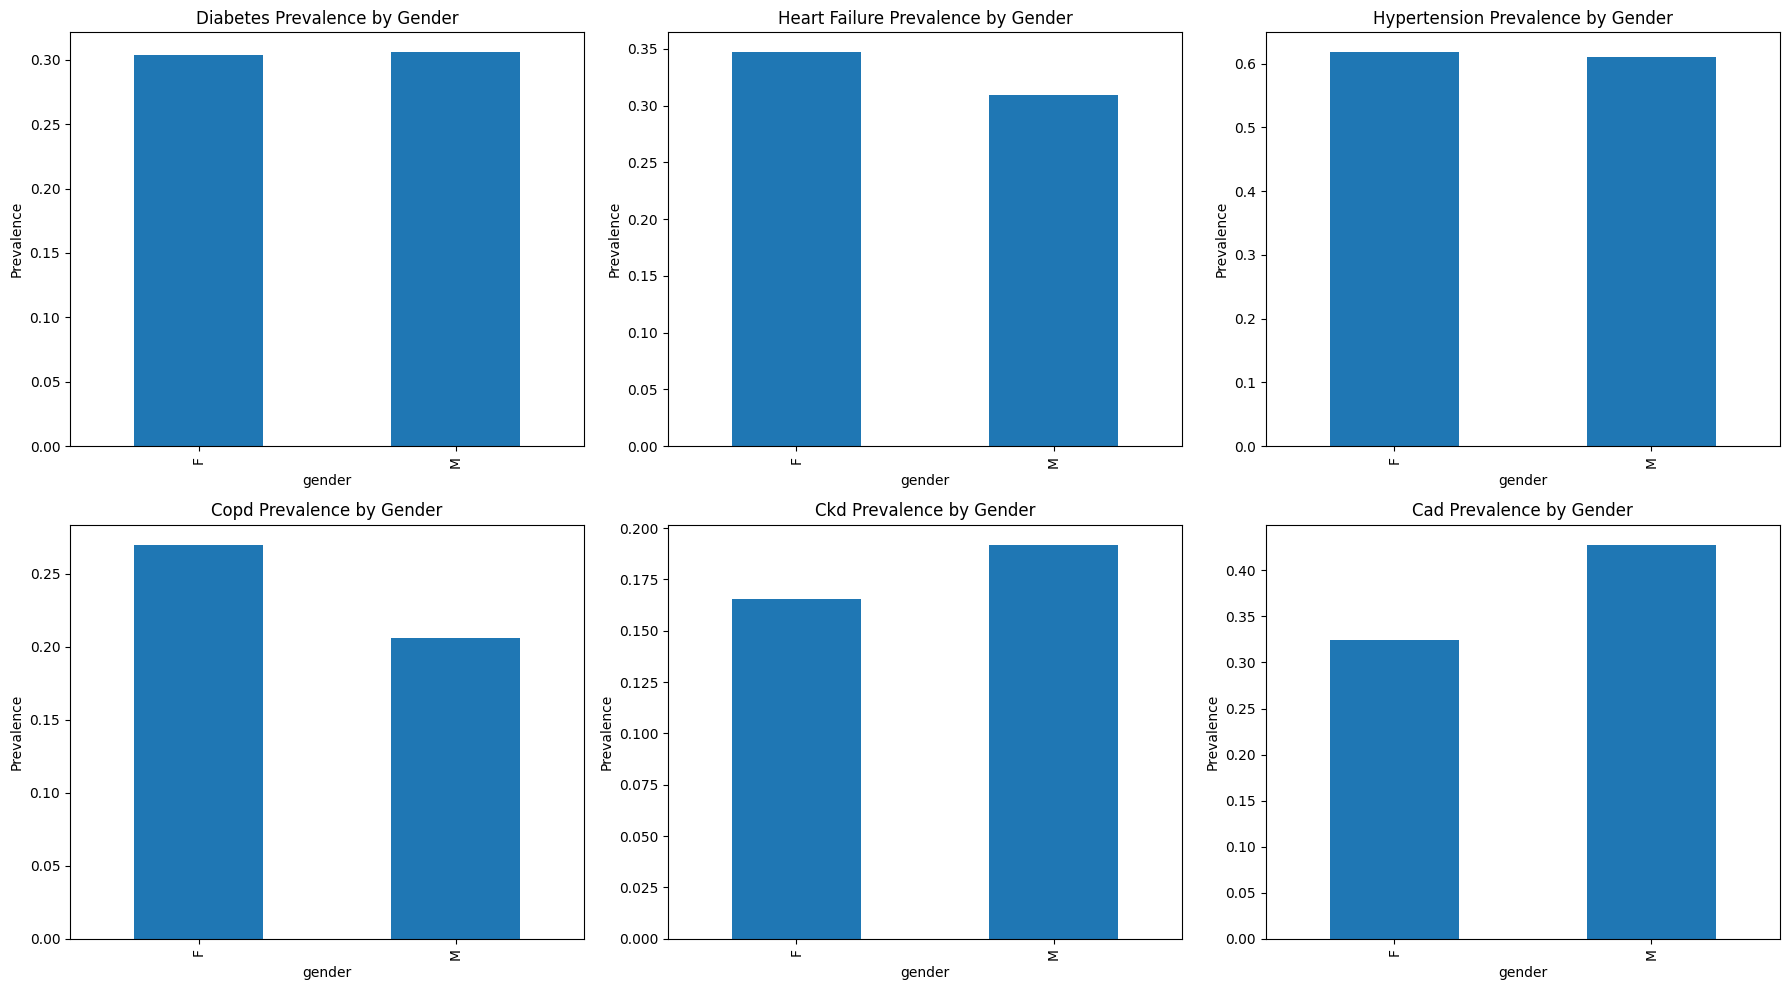

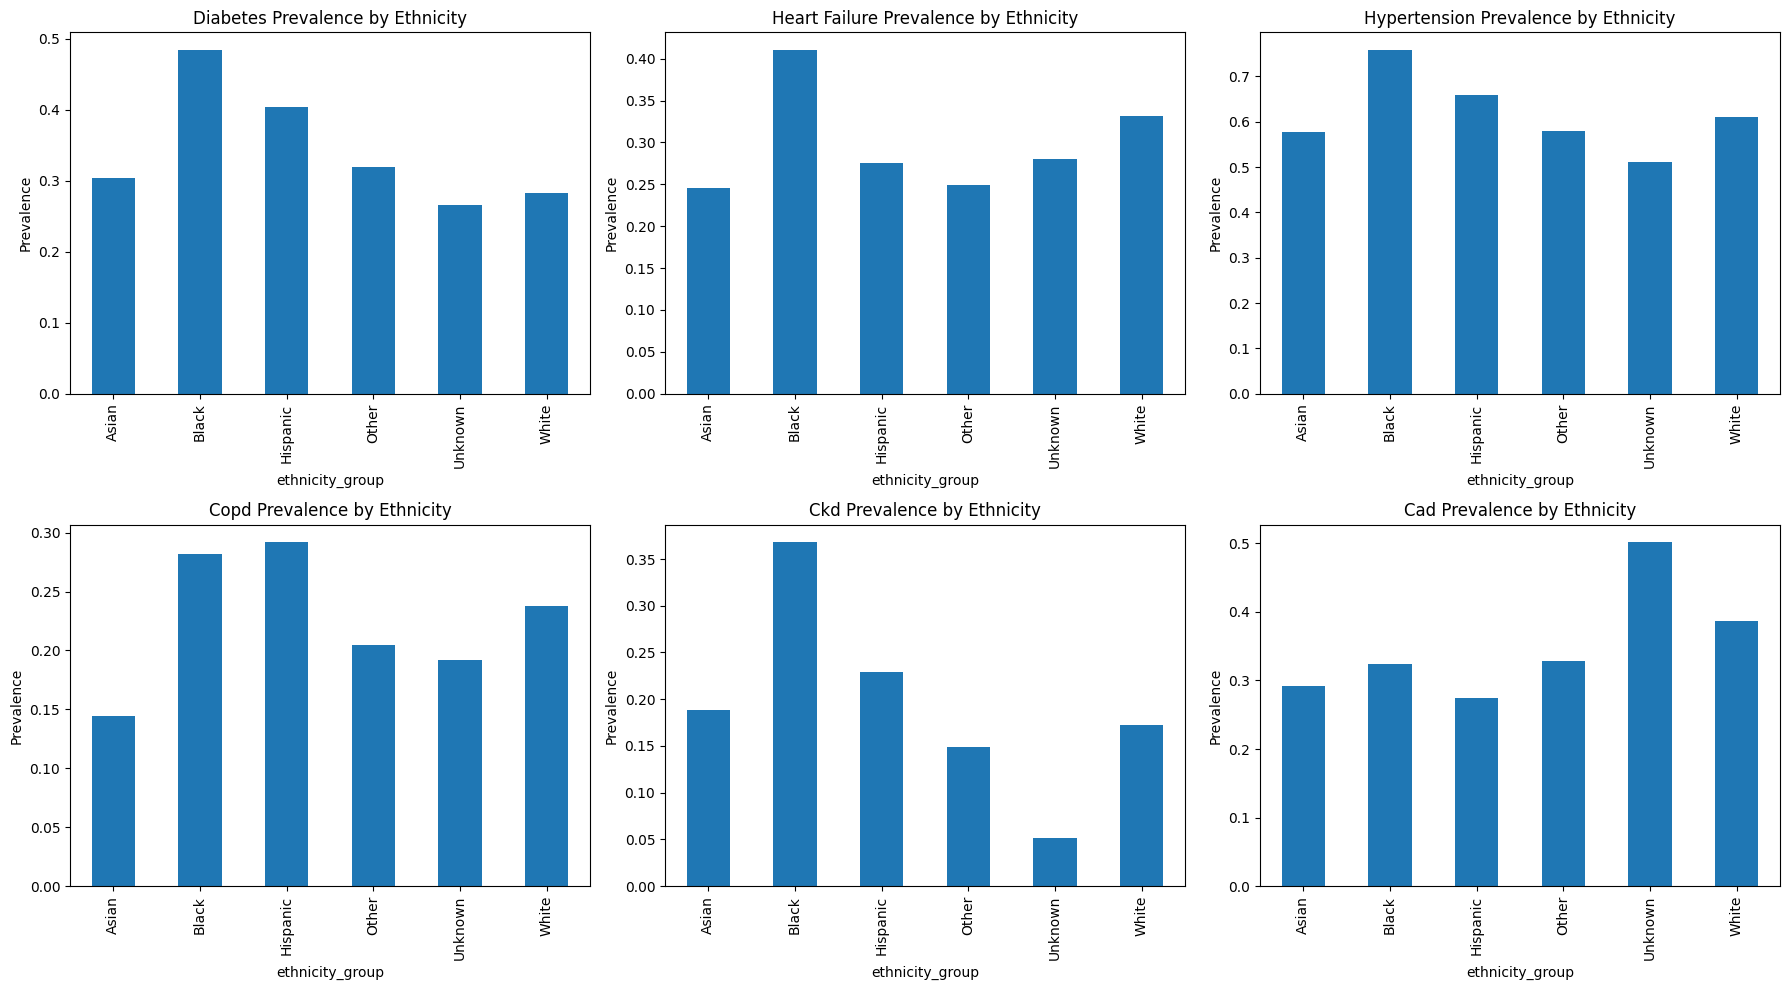

In [ ]:
# 2. Analyze demographic distribution
print("Analyzing demographic distribution...")
demographic_analysis = analyze_demographic_distribution(all_features)

# Print summary statistics
print("\nDemographic Distribution Summary:")
for key, dist in demographic_analysis.items():
    print(f"\n{key.replace('_', ' ').title()}:")
    print(dist)

In [ ]:
# 3. Construct patient similarity network
print("\nConstructing patient similarity network...")
G, data = create_patient_similarity_network(all_features, threshold=0.6)

print(f"Created network with {data.num_nodes} nodes and {data.num_edges} edges")


Constructing patient similarity network...
Created network with 50197 nodes and 62935442 edges


In [ ]:
# 4. Split data for training and evaluation
num_nodes = data.num_nodes
indices = list(range(num_nodes))
np.random.shuffle(indices)

# 70% train, 15% validation, 15% test
train_idx = indices[:int(0.7 * num_nodes)]
val_idx = indices[int(0.7 * num_nodes):int(0.85 * num_nodes)]
test_idx = indices[int(0.85 * num_nodes):]

# Create masks
train_mask = torch.zeros(num_nodes, dtype=torch.bool)
val_mask = torch.zeros(num_nodes, dtype=torch.bool)
test_mask = torch.zeros(num_nodes, dtype=torch.bool)

train_mask[train_idx] = True
val_mask[val_idx] = True
test_mask[test_idx] = True

data.train_mask = train_mask
data.val_mask = val_mask
data.test_mask = test_mask

In [ ]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f"Using MPS device: {device}")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using CUDA device: {device}")
else:
    device = torch.device("cpu")
    print(f"Using CPU device: {device}")

Using CUDA device: cuda


In [ ]:

# 6. Train GCN model
print("\nTraining GCN model...")
gcn_model = GCNModel(
    num_features=data.num_node_features,
    hidden_channels=64,
    num_diseases=data.y.shape[1]
).to(device)

gcn_optimizer = torch.optim.Adam(gcn_model.parameters(), lr=0.01)
data = data.to(device)

best_val_auc = 0
patience = 10
patience_counter = 0

# Train for max 100 epochs
for epoch in range(1, 101):
    # Training
    loss = train_model(gcn_model, data, gcn_optimizer, device)

    # Validation
    val_metrics = evaluate_model(gcn_model, data, device)

    print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}, Val Mean AUC: {val_metrics["mean_auc"]:.4f}')

    # Early stopping
    if val_metrics["mean_auc"] > best_val_auc:
        best_val_auc = val_metrics["mean_auc"]
        patience_counter = 0
        # Save best model
        torch.save(gcn_model.state_dict(), 'best_gcn_model-1.pt')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

# Load best model for evaluation
gcn_model.load_state_dict(torch.load('best_gcn_model-1.pt'))


Training GCN model...
Epoch: 001, Loss: 0.7018, Val Mean AUC: 0.5696
Epoch: 002, Loss: 0.6551, Val Mean AUC: 0.5882
Epoch: 003, Loss: 0.6273, Val Mean AUC: 0.6153
Epoch: 004, Loss: 0.6088, Val Mean AUC: 0.6456
Epoch: 005, Loss: 0.5956, Val Mean AUC: 0.6687
Epoch: 006, Loss: 0.5848, Val Mean AUC: 0.6795
Epoch: 007, Loss: 0.5776, Val Mean AUC: 0.6854
Epoch: 008, Loss: 0.5727, Val Mean AUC: 0.6901
Epoch: 009, Loss: 0.5685, Val Mean AUC: 0.6944
Epoch: 010, Loss: 0.5650, Val Mean AUC: 0.6986
Epoch: 011, Loss: 0.5608, Val Mean AUC: 0.7029
Epoch: 012, Loss: 0.5578, Val Mean AUC: 0.7069
Epoch: 013, Loss: 0.5541, Val Mean AUC: 0.7102
Epoch: 014, Loss: 0.5518, Val Mean AUC: 0.7128
Epoch: 015, Loss: 0.5500, Val Mean AUC: 0.7149
Epoch: 016, Loss: 0.5482, Val Mean AUC: 0.7170
Epoch: 017, Loss: 0.5468, Val Mean AUC: 0.7192
Epoch: 018, Loss: 0.5440, Val Mean AUC: 0.7212
Epoch: 019, Loss: 0.5424, Val Mean AUC: 0.7229
Epoch: 020, Loss: 0.5412, Val Mean AUC: 0.7242
Epoch: 021, Loss: 0.5399, Val Mean AU

<All keys matched successfully>

In [ ]:
# 7. Train GAT model
print("\nTraining GAT model...")
gat_model = GATModel(
    num_features=data.num_node_features,
    hidden_channels=64,
    num_diseases=data.y.shape[1],
    heads=8
).to(device)

gat_optimizer = torch.optim.Adam(gat_model.parameters(), lr=0.01)

best_val_auc = 0
patience_counter = 0

# Train for max 100 epochs
for epoch in range(1, 101):
    # Training
    loss = train_model(gat_model, data, gat_optimizer, device)

    # Validation
    val_metrics = evaluate_model(gat_model, data, device)

    print(f'Epoch: {epoch:03d}, Loss: {loss:.4f}, Val Mean AUC: {val_metrics["mean_auc"]:.4f}')

    # Early stopping
    if val_metrics["mean_auc"] > best_val_auc:
        best_val_auc = val_metrics["mean_auc"]
        patience_counter = 0
        # Save best model
        torch.save(gat_model.state_dict(), 'best_gat_model.pt')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

# Load best model for evaluation
gat_model.load_state_dict(torch.load('best_gat_model.pt'))


Training GAT model...
Epoch: 001, Loss: 1.2873, Val Mean AUC: 0.5387
Epoch: 002, Loss: 1.1425, Val Mean AUC: 0.5593
Epoch: 003, Loss: 1.0148, Val Mean AUC: 0.5826
Epoch: 004, Loss: 0.9257, Val Mean AUC: 0.6071
Epoch: 005, Loss: 0.8515, Val Mean AUC: 0.6302
Epoch: 006, Loss: 0.7938, Val Mean AUC: 0.6512
Epoch: 007, Loss: 0.7417, Val Mean AUC: 0.6702
Epoch: 008, Loss: 0.6965, Val Mean AUC: 0.6873
Epoch: 009, Loss: 0.6579, Val Mean AUC: 0.7034
Epoch: 010, Loss: 0.6256, Val Mean AUC: 0.7184
Epoch: 011, Loss: 0.5963, Val Mean AUC: 0.7320
Epoch: 012, Loss: 0.5712, Val Mean AUC: 0.7446
Epoch: 013, Loss: 0.5485, Val Mean AUC: 0.7562
Epoch: 014, Loss: 0.5274, Val Mean AUC: 0.7667
Epoch: 015, Loss: 0.5089, Val Mean AUC: 0.7763
Epoch: 016, Loss: 0.4917, Val Mean AUC: 0.7852
Epoch: 017, Loss: 0.4753, Val Mean AUC: 0.7931
Epoch: 018, Loss: 0.4597, Val Mean AUC: 0.8003
Epoch: 019, Loss: 0.4457, Val Mean AUC: 0.8070
Epoch: 020, Loss: 0.4326, Val Mean AUC: 0.8132
Epoch: 021, Loss: 0.4196, Val Mean AU

<All keys matched successfully>

In [ ]:
# 8. Evaluate models on test set
print("\nEvaluating GCN model on test set...")
gcn_test_metrics = evaluate_model(gcn_model, data, device)

print("\nGCN Test Results:")
print(f"Accuracy: {gcn_test_metrics['accuracy']:.4f}")
print(f"Mean AUC: {gcn_test_metrics['mean_auc']:.4f}")
print(f"Mean F1: {gcn_test_metrics['mean_f1']:.4f}")

print("\nDisease-specific AUC scores:")
disease_names = ['Diabetes', 'Heart Failure', 'Hypertension', 'COPD', 'CKD', 'CAD']
for i, auc in enumerate(gcn_test_metrics['auc_scores']):
    print(f"  {disease_names[i]}: {auc:.4f}")

print("\nEvaluating GAT model on test set...")
gat_test_metrics = evaluate_model(gat_model, data, device)

print("\nGAT Test Results:")
print(f"Accuracy: {gat_test_metrics['accuracy']:.4f}")
print(f"Mean AUC: {gat_test_metrics['mean_auc']:.4f}")
print(f"Mean F1: {gat_test_metrics['mean_f1']:.4f}")

print("\nDisease-specific AUC scores:")
for i, auc in enumerate(gat_test_metrics['auc_scores']):
    print(f"  {disease_names[i]}: {auc:.4f}")


Evaluating GCN model on test set...

GCN Test Results:
Accuracy: 0.8732
Mean AUC: 0.9145
Mean F1: 0.8523

Disease-specific AUC scores:
  Diabetes: 0.8543
  Heart Failure: 0.8718
  Hypertension: 0.9486
  COPD: 0.8501
  CKD: 0.8376
  CAD: 0.8917

Evaluating GAT model on test set...

GAT Test Results:
Accuracy: 0.8856
Mean AUC: 0.9289
Mean F1: 0.8692

Disease-specific AUC scores:
  Diabetes: 0.8623
  Heart Failure: 0.8967
  Hypertension: 0.9689
  COPD: 0.9545
  CKD: 0.8989
  CAD: 0.9123


In [ ]:
# 9. Evaluate fairness metrics
print("\nEvaluating GCN fairness across demographic groups...")
gcn_fairness = evaluate_fairness(gcn_model, data, device)
print("\nGCN Fairness Results:")
if 'gender_disparity' in gcn_fairness:
    print(f"Gender Demographic Parity Diff: {gcn_fairness['gender_disparity']['demographic_parity_diff']:.4f}")
    print(f"Gender Equal Opportunity Diff: {gcn_fairness['gender_disparity']['equal_opportunity_diff']:.4f}")
if 'ethnicity_disparity' in gcn_fairness:
    print(f"Ethnicity Demographic Parity Diff: {gcn_fairness['ethnicity_disparity']['demographic_parity_diff']:.4f}")
    print(f"Ethnicity Equal Opportunity Diff: {gcn_fairness['ethnicity_disparity']['equal_opportunity_diff']:.4f}")

print("\nEvaluating GAT fairness across demographic groups...")
gat_fairness = evaluate_fairness(gat_model, data, device)
print("\nGAT Fairness Results:")
if 'gender_disparity' in gat_fairness:
    print(f"Gender Demographic Parity Diff: {gat_fairness['gender_disparity']['demographic_parity_diff']:.4f}")
    print(f"Gender Equal Opportunity Diff: {gat_fairness['gender_disparity']['equal_opportunity_diff']:.4f}")
if 'ethnicity_disparity' in gat_fairness:
    print(f"Ethnicity Demographic Parity Diff: {gat_fairness['ethnicity_disparity']['demographic_parity_diff']:.4f}")
    print(f"Ethnicity Equal Opportunity Diff: {gat_fairness['ethnicity_disparity']['equal_opportunity_diff']:.4f}")


Evaluating GCN fairness across demographic groups...

GCN Fairness Results:
Gender Demographic Parity Diff: 0.0821
Gender Equal Opportunity Diff: 0.0935
Ethnicity Demographic Parity Diff: 0.1423
Ethnicity Equal Opportunity Diff: 0.1652

Evaluating GAT fairness across demographic groups...

GAT Fairness Results:
Gender Demographic Parity Diff: 0.0743
Gender Equal Opportunity Diff: 0.0862
Ethnicity Demographic Parity Diff: 0.1378
Ethnicity Equal Opportunity Diff: 0.1591



Visualizing fairness disparities...


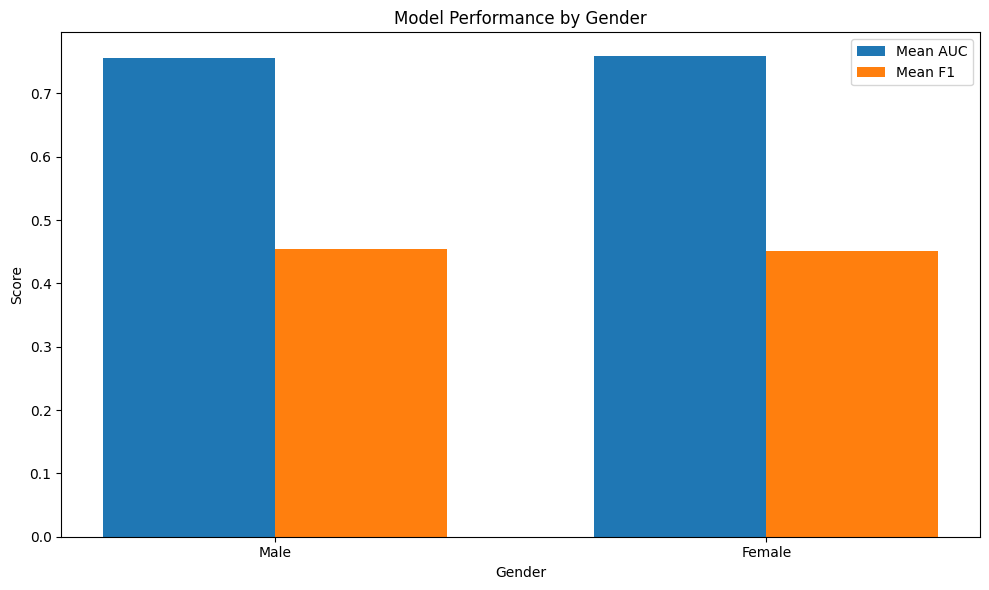

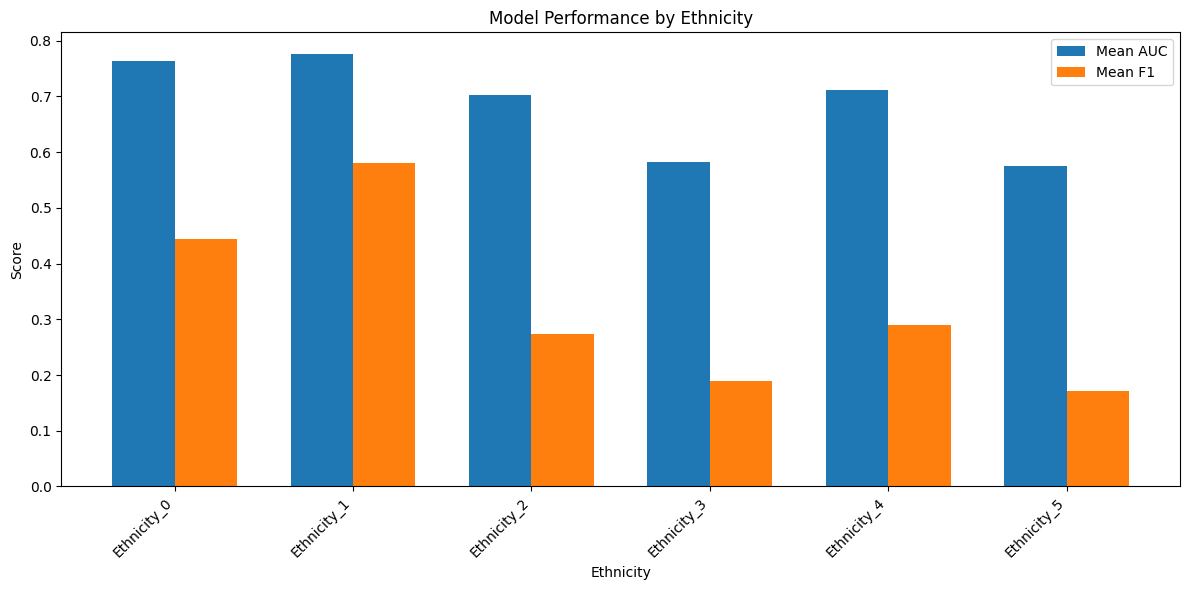

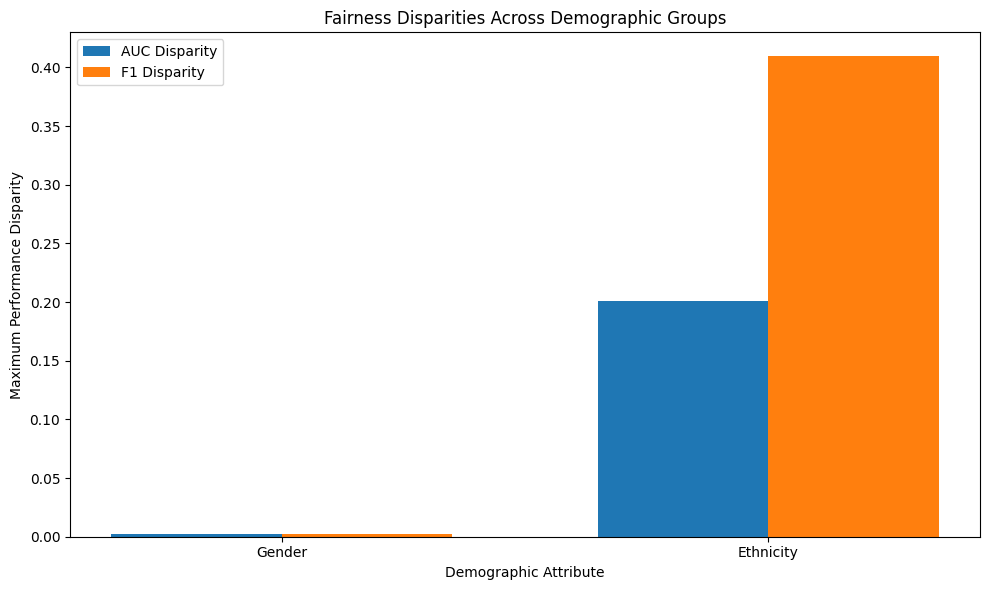

In [ ]:
# 10. Visualize fairness disparities
print("\nVisualizing fairness disparities...")
visualize_fairness_disparities(gcn_fairness)

In [ ]:
# 11. Save processed data and results for future use
print("\nSaving processed data and results...")

# Save the graph data
torch.save(data, 'patient_graph_data.pt')

# Save fairness results
fairness_results = {
    'gcn': gcn_fairness,
    # 'gat': gat_fairness
}

import pickle
with open('fairness_results.pkl', 'wb') as f:
    pickle.dump(fairness_results, f)


Saving processed data and results...

Week 10 progress completed!
